In [90]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # must be set BEFORE importing keras

from pathlib import Path
import time

import h5py                              # reads the .h5 file
import numpy as np                       # numerical arrays
import pandas as pd                      # tables
import matplotlib.pyplot as plt          # plots
import torch                             # compute engine used by Keras
import keras
from keras import layers                 # network building blocks (Conv1D, Dense, ...)
from sklearn.decomposition import PCA
from numpy.lib.stride_tricks import sliding_window_view   # cuts the windows
from IPython.display import display

get_ipython().run_line_magic("matplotlib", "inline")      # plots appear below the cell

path = Path("data") / "data_100Hz.h5"   # put the dataset in the data folder next to this notebook

# --- settings ---
TARGET = "SB01_x"                         # strain channel to predict
N_PC = 25                                 # number of principal components to keep
fs = 100                                  # sampling frequency [Hz]
SEED = 0                                  # fixed random seed: same results at every run

LONG_WIN = 500                           # window length in samples (1000 samples = 10 s)
OVERLAP = 0.1                            # overlap between consecutive windows (10 %)
STRIDE = max(1, int(round(LONG_WIN * (1 - OVERLAP))))     # shift between window starts, in samples (900)

SPLIT = (0.70, 0.15, 0.15)                # fractions of each recording, in time order: train, validation, test
assert abs(sum(SPLIT) - 1) < 1e-9, "SPLIT fractions must add up to 1"

assert Path(path).is_file(), "File not found: check the path"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"   # NVIDIA GPU if available, otherwise CPU
print("Keras", keras.__version__, "| backend:", keras.backend.backend(),
      "| PyTorch", torch.__version__, "| device:", DEVICE)

ADD_NOISE_TO_TRAINING = False              # True: the undamaged noise-mode recordings are added to the training set; False: sweeps only

Keras 3.16.0.dev2026110303 | backend: torch | PyTorch 2.15.0+cu132 | device: cuda


## 2 Recordings

The recordings used are the **undamaged (UDS) sweep (SM) recordings**: 2 shaker positions (P1, P2), 2 directions (Y, Z) and 2 repetitions, 8 recordings in total. The noise-mode recordings (NM) are excluded.

In [91]:
with h5py.File(path, "r") as f:
    all_names = list(f.keys())                                    # names of all recordings in the file

rows = []
for n in all_names:
    _, position, state, mode, direction, rep = n.split("_")       # "MVS_P1_UDS_SM_Y_02" -> P1, UDS, SM, Y, 02
    rows.append({"name": n, "position": position, "state": state,
                 "mode": mode, "direction": direction, "rep": rep})
meta_all = pd.DataFrame(rows)                                     # one row per recording in the file

is_uds = meta_all["state"] == "UDS"                               # undamaged recordings
meta = meta_all[is_uds & (meta_all["mode"] == "SM")].reset_index(drop=True)    # undamaged sweep recordings: train, validation and test
rec_names = list(meta["name"])                                    # the 8 sweep recordings
noise_names = list(meta_all[is_uds & (meta_all["mode"] == "NM")]["name"]) if ADD_NOISE_TO_TRAINING else []   # undamaged noise recordings: training only
used_names = rec_names + noise_names                              # every recording that gets loaded
display(meta)
print("Noise recordings added to the training set:", noise_names)

,name,position,state,mode,direction,rep
0,MVS_P1_UDS_SM_Y_01,P1,UDS,SM,Y,01
1,MVS_P1_UDS_SM_Y_02,P1,UDS,SM,Y,02
2,MVS_P1_UDS_SM_Z_01,P1,UDS,SM,Z,01
3,MVS_P1_UDS_SM_Z_02,P1,UDS,SM,Z,02
4,MVS_P2_UDS_SM_Y_01,P2,UDS,SM,Y,01
5,MVS_P2_UDS_SM_Y_02,P2,UDS,SM,Y,02
6,MVS_P2_UDS_SM_Z_01,P2,UDS,SM,Z,01
7,MVS_P2_UDS_SM_Z_02,P2,UDS,SM,Z,02


Noise recordings added to the training set: []


## 3 Loading

`load_recording` reads one recording from the HDF5 file (test → sensor type → sensor → axis) and returns a table with one column per channel and one row per sample, plus the unit of the target.
Only the 75 acceleration channels and the target are loaded, in `float32`.

In [92]:
def is_wanted(ch):
    return ch.startswith("AL") or (ch.startswith("AG") and ch.endswith(("_y", "_z"))) or ch == TARGET   # 75 accelerations + target

def load_recording(name):
    cols = {}
    with h5py.File(path, "r") as f:
        for group in ("acceleration", "strain"):
            for sensor in f[name][group]:
                for axis in f[name][group][sensor]:
                    ch = f"{sensor}_{axis}"                                           # channel name, e.g. AG01_y
                    if is_wanted(ch):                                                 # load only the channels we need
                        cols[ch] = f[name][group][sensor][axis][:].astype("float32")  # read all values, float32 to save memory
        unit = f[name]["strain"][TARGET.split("_")[0]].attrs["unit"]                  # unit of the target
    d = pd.DataFrame(cols)                                                            # one column per channel
    d.index = np.arange(len(d)) / fs                                                  # time in seconds
    d.index.name = "Time [s]"
    return d, unit

recordings, units = {}, set()   #dafinizione del dataset
for n in used_names:                                                                  # sweep recordings first, then the noise ones
    d, u = load_recording(n)
    recordings[n] = d                                                                 # table of this recording
    units.add(u)

acc_cols = sorted(c for c in recordings[rec_names[0]].columns if c != TARGET)         # the 75 acceleration channels, in alphabetical order
assert len(acc_cols) == 75, len(acc_cols)
for n in used_names:
    assert set(recordings[n].columns) == set(acc_cols) | {TARGET}, n                  # check: same channels in every recording
    recordings[n] = recordings[n][acc_cols + [TARGET]]                                # same column order everywhere
assert len(units) == 1                                                                # check: same unit in every recording
target_unit = units.pop()

for n, d in recordings.items():
    print(f"{n}: {len(d)} samples ({len(d) / fs:.0f} s)")
print("Target unit:", target_unit)
display(recordings[rec_names[0]].head())

MVS_P1_UDS_SM_Y_01: 62147 samples (621 s)
MVS_P1_UDS_SM_Y_02: 61681 samples (617 s)
MVS_P1_UDS_SM_Z_01: 62410 samples (624 s)
MVS_P1_UDS_SM_Z_02: 62531 samples (625 s)
MVS_P2_UDS_SM_Y_01: 62386 samples (624 s)
MVS_P2_UDS_SM_Y_02: 62520 samples (625 s)
MVS_P2_UDS_SM_Z_01: 62335 samples (623 s)
MVS_P2_UDS_SM_Z_02: 62382 samples (624 s)
Target unit: MPa


,AG01_y,AG01_z,AG02_y,AG02_z,AG03_y,AG03_z,AG04_y,AG04_z,AG05_y,AG05_z,...,AL32_z,AL33_z,AL34_z,AL35_z,AL36_z,AL37_z,AL38_z,AL39_z,AL40_z,SB01_x
Time [s],,,,,,,,,,,,,,,,,,,,,
0.00,0.000058,0.001092,-0.011348,0.008771,0.000409,0.000413,0.005028,0.003098,-0.000492,0.002269,...,0.009926,0.000973,-0.001352,0.000936,-0.000134,0.000465,0.000693,0.000564,0.000754,0.767691
0.01,-0.000032,0.000821,-0.012555,0.008673,0.000168,-0.000498,0.005462,0.002743,-0.001115,0.001427,...,0.009305,0.001137,-0.000475,0.001530,-0.000516,0.000505,0.000588,0.000314,0.000867,0.054280
0.02,0.000777,0.000395,-0.013792,0.008423,0.000177,-0.000644,0.005892,0.002216,-0.000786,0.000745,...,0.008656,0.000647,-0.000247,0.000791,-0.000762,0.000456,0.001013,0.001129,0.001352,0.405942
0.03,0.001225,0.000077,-0.014491,0.008877,-0.000285,-0.000844,0.006455,0.002084,-0.000660,0.000369,...,0.008078,-0.000027,-0.000399,0.000673,-0.000927,0.000251,0.001025,0.000447,0.000897,0.336386
0.04,0.001112,0.000016,-0.014792,0.009201,-0.000513,-0.001504,0.007108,0.002263,-0.000784,0.000115,...,0.007338,-0.000446,-0.000980,0.000357,-0.001249,0.000384,0.000642,-0.000073,0.000195,0.247985


## 4 PCA on all the recordings

The 75 acceleration channels are strongly correlated, so the PCA replaces them with `N_PC` principal components (set in cell 1).

The PCA is the **first** step after loading, before the split: it is fitted on **all the samples of all the recordings** and then applied to each recording.
Its mean and directions therefore come from the whole data, including the parts that later become validation and test. The PCA only uses the accelerations, never the target.
It only subtracts the mean of each channel; it does not divide by the standard deviation.

In [93]:
X_all = np.concatenate([d[acc_cols].values for d in recordings.values()])   # all the recordings stacked: (total samples, 75)

pca = PCA(n_components=N_PC)                                  # PCA with N_PC components
pca.fit(X_all)                                                # mean and directions computed on ALL the recordings
print(f"Explained variance with {N_PC} components: {100 * pca.explained_variance_ratio_.sum():.2f} %")

pc_cols = [f"PC{i + 1}" for i in range(N_PC)]                 # column names: PC1, PC2, ...
reduced_full = {}                                             # recording name -> PCs + target, the whole recording
for n, d in recordings.items():
    r = pd.DataFrame(pca.transform(d[acc_cols].values), index=d.index, columns=pc_cols).astype("float32")   # apply the PCA to this recording
    r[TARGET] = d[TARGET].values                              # add the target as last column
    reduced_full[n] = r

for n, d in recordings.items():                               # how much information the PCA keeps in each recording
    x = d[acc_cols].values - pca.mean_                        # subtract the PCA mean
    rec = x @ pca.components_.T @ pca.components_             # reconstruction to 75 channels from the PCs
    kept = 1 - ((x - rec) ** 2).sum() / (x ** 2).sum()        # 1 - (energy lost / total energy)
    print(f"{n}: information kept {100 * kept:.2f} %")

display(reduced_full[rec_names[0]].head())

Explained variance with 25 components: 97.78 %
MVS_P1_UDS_SM_Y_01: information kept 97.22 %
MVS_P1_UDS_SM_Y_02: information kept 97.60 %
MVS_P1_UDS_SM_Z_01: information kept 97.52 %
MVS_P1_UDS_SM_Z_02: information kept 98.09 %
MVS_P2_UDS_SM_Y_01: information kept 97.76 %
MVS_P2_UDS_SM_Y_02: information kept 98.16 %
MVS_P2_UDS_SM_Z_01: information kept 97.75 %
MVS_P2_UDS_SM_Z_02: information kept 98.22 %


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,...,PC17,PC18,PC19,PC20,PC21,PC22,PC23,PC24,PC25,SB01_x
Time [s],,,,,,,,,,,,,,,,,,,,,
0.00,0.004769,-0.000326,0.002402,-0.000615,-0.001594,-0.004943,-0.005985,-0.001369,0.001156,-0.003058,...,0.004697,0.001255,0.001270,-0.005555,-0.000465,0.002589,0.003828,0.002181,0.002131,0.767691
0.01,0.004266,-0.000964,0.002796,0.000367,-0.001847,-0.003162,-0.006956,-0.000485,0.001197,-0.003774,...,0.004611,0.002010,0.001349,-0.006721,-0.001363,0.002726,0.003945,0.002090,0.001953,0.054280
0.02,0.004035,-0.001104,0.003256,0.001249,-0.002569,-0.003571,-0.006831,0.000462,0.001840,-0.004962,...,0.004330,0.002659,0.001293,-0.006603,-0.001822,0.002344,0.003672,0.000212,0.002152,0.405942
0.03,0.003661,-0.001332,0.004096,0.001639,-0.003449,-0.003486,-0.006153,0.001735,0.002396,-0.005764,...,0.003217,0.002490,0.001479,-0.007414,-0.002611,0.001306,0.003929,-0.000140,0.001857,0.336386
0.04,0.002876,-0.001243,0.005198,0.001361,-0.003966,-0.003319,-0.005075,0.002671,0.002986,-0.006323,...,0.002971,0.002612,0.001954,-0.008499,-0.003727,0.000668,0.003886,-0.000655,0.001431,0.247985


## 5 Chronological split

Each recording, already reduced to its principal components, is cut along time: the first part (`SPLIT[0]`) is training, the next part (`SPLIT[1]`) is validation and the last part (`SPLIT[2]`) is test. Nothing is shuffled.
The same cut points are applied to the raw channels (`blocks_raw`, used by the plots) and to the PCs (`reduced`, used to build the windows).

In [94]:
def make_windows(d, win, stride):
    assert len(d) >= win, "recording shorter than one window"  # check: at least one window fits
    Z = d[pc_cols].values.astype("float32")                   # inputs: the PCs, array (rows, N_PC)
    y = d[TARGET].values.astype("float32")                    # target: array (rows,)
    X = sliding_window_view(Z, win, axis=0)                   # all possible windows: (windows, N_PC, win)
    X = np.ascontiguousarray(X.transpose(0, 2, 1)[::stride])  # reorder to (windows, win, N_PC) and keep one window every `stride`
    y_win = y[win - 1:][::stride]                             # target of each window = value at its LAST sample
    t_end = d.index.values[win - 1:][::stride]                # time (in seconds) of the last sample of each window
    return X, y_win, t_end

windows = {}                                                  # recording name -> (inputs, targets, end times) of ALL its windows
for n, r in reduced_full.items():                             # the PCs of the whole recording
    windows[n] = make_windows(r, LONG_WIN, STRIDE)
    X, y, t = windows[n]
    print(f"{n}: X={X.shape}   y={y.shape}   ({LONG_WIN} samples per window, one every {STRIDE} samples)")

MVS_P1_UDS_SM_Y_01: X=(137, 500, 25)   y=(137,)   (500 samples per window, one every 450 samples)
MVS_P1_UDS_SM_Y_02: X=(136, 500, 25)   y=(136,)   (500 samples per window, one every 450 samples)
MVS_P1_UDS_SM_Z_01: X=(138, 500, 25)   y=(138,)   (500 samples per window, one every 450 samples)
MVS_P1_UDS_SM_Z_02: X=(138, 500, 25)   y=(138,)   (500 samples per window, one every 450 samples)
MVS_P2_UDS_SM_Y_01: X=(138, 500, 25)   y=(138,)   (500 samples per window, one every 450 samples)
MVS_P2_UDS_SM_Y_02: X=(138, 500, 25)   y=(138,)   (500 samples per window, one every 450 samples)
MVS_P2_UDS_SM_Z_01: X=(138, 500, 25)   y=(138,)   (500 samples per window, one every 450 samples)
MVS_P2_UDS_SM_Z_02: X=(138, 500, 25)   y=(138,)   (500 samples per window, one every 450 samples)


## SLIDING WINDOWS


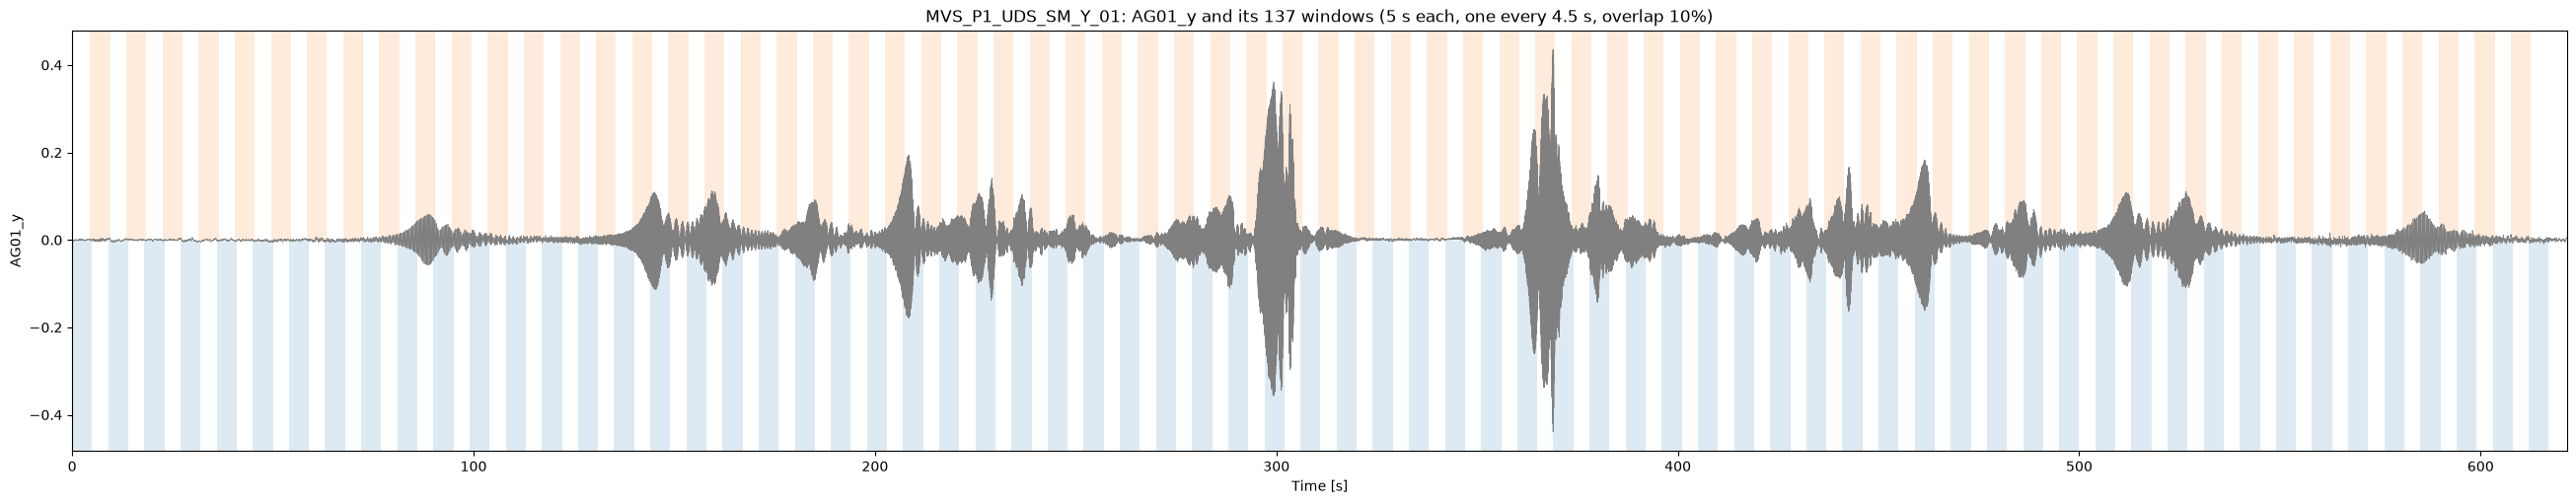

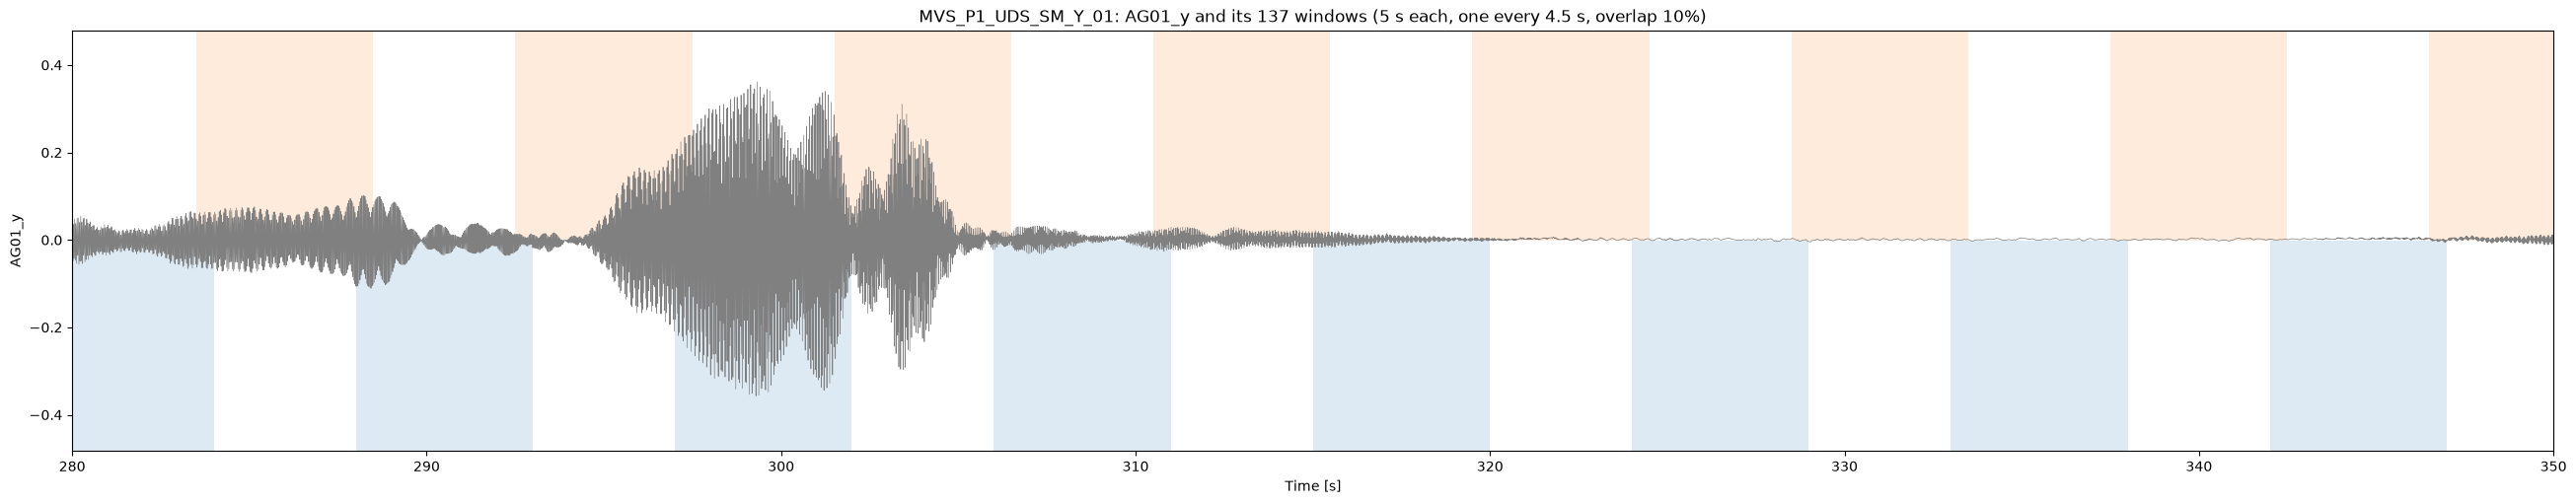

In [95]:
def plot_windows(n, channel=None, t_range=None, fig_size=(26, 5)):
    """An acceleration channel with a translucent rectangle over the part of the recording covered by each window."""
    d = recordings[n]
    channel = channel or acc_cols[0]                          # channel to draw: the first acceleration channel by default
    t_end = windows[n][2]                                     # time of the last sample of each window
    t_start = t_end - (LONG_WIN - 1) / fs                     # time of the first sample of each window
    n_rows = int(np.ceil(LONG_WIN / STRIDE))                  # overlapping windows get different colours and different bands
    t_range = t_range or (d.index[0], d.index[-1])            # time interval to show: the whole recording by default
    visible = [k for k in range(len(t_end)) if t_end[k] >= t_range[0] and t_start[k] <= t_range[1]]

    fig, ax1 = plt.subplots(figsize=fig_size, constrained_layout=True)
    ax1.plot(d.index, d[channel], color="grey", lw=0.5)      # the acceleration channel
    for k in visible:
        c = f"C{k % n_rows % 10}"                             # colour = band of the window: neighbouring windows differ
        row = k % n_rows                                      # band of this window: 0 = lowest band of the plot
        ax1.axvspan(t_start[k], t_end[k], ymin=row / n_rows, ymax=(row + 1) / n_rows,
                    color=c, alpha=0.15, lw=0)                # translucent rectangle, only in its band of the plot height
    ax1.set_xlim(*t_range)
    ax1.set(title=f"{n}: {channel} and its {len(t_end)} windows ({LONG_WIN / fs:g} s each, one every {STRIDE / fs:g} s, overlap {OVERLAP:.0%})",
            xlabel="Time [s]", ylabel=channel)
    plt.show()
    return fig

plot_windows(rec_names[0])                                    # the whole first recording
plot_windows(rec_names[0], t_range=(280, 350));                # zoom on 40 s, around a burst

## 6 Shuffle and split

In [96]:
train_parts = []     # will hold one piece per recording: the windows that go to training
val_parts = []       # same for validation
test_parts = []      # same for test

rng = np.random.default_rng(SEED)     # random generator with a fixed seed: same split at every run

for rec_id, n in enumerate(used_names):     # one recording at a time
    X, y, t = windows[n]                    # all the windows of this recording
    n_w = len(X)                            # how many windows
    order = rng.permutation(n_w)     # the window numbers 0 ... n_w-1 in random order
    n_train = round(SPLIT[0] * n_w)     # windows of this recording that go to training (70 %)
    n_val = round(SPLIT[1] * n_w)       # windows that go to validation (15 %)

    idx_train = order[:n_train]                   # the first n_train shuffled numbers
    idx_val = order[n_train:n_train + n_val]      # the next n_val
    idx_test = order[n_train + n_val:]            # all the rest: test (15 %)

    train_parts.append((X[idx_train], y[idx_train], t[idx_train], np.full(len(idx_train), rec_id)))
    val_parts.append((X[idx_val], y[idx_val], t[idx_val], np.full(len(idx_val), rec_id)))
    test_parts.append((X[idx_test], y[idx_test], t[idx_test], np.full(len(idx_test), rec_id)))

def stack(parts, k):
    return np.concatenate([p[k] for p in parts])     # join the pieces of all recordings into one array

X_train, y_train_phys, t_train, rec_train = (stack(train_parts, k) for k in range(4))
X_val, y_val_phys, t_val, rec_val = (stack(val_parts, k) for k in range(4))
X_test, y_test_phys, t_test, rec_test = (stack(test_parts, k) for k in range(4))

for name, X, y in [("train", X_train, y_train_phys), ("val", X_val, y_val_phys), ("test", X_test, y_test_phys)]:
    print(f"{name:5s} X={X.shape}   y={y.shape}   target mean {y.mean():+.4f}   std {y.std():.4f} {target_unit}")

train X=(773, 500, 25)   y=(773,)   target mean -0.0057   std 0.1296 MPa
val   X=(167, 500, 25)   y=(167,)   target mean -0.0042   std 0.1331 MPa
test  X=(161, 500, 25)   y=(161,)   target mean +0.0109   std 0.1321 MPa


## 7 CNN architecture

The network is a **causal temporal convolutional network** (TCN). It reads one window of 1000 time steps and 20 principal components, and returns one number: the predicted strain at the **last** time step of the window.

### Data shapes

| Stage | Shape (batch, time, channels) | Parameters |
|---|---|---|
| Input window | (batch, 1000, 20) | 0 |
| Pointwise projection `Conv1D(16, kernel 1)` | (batch, 1000, 16) | (20 + 1) × 16 = 336 |
| 8 residual blocks, each: causal `Conv1D(16, kernel 5)` + skip connection + ReLU | (batch, 1000, 16) | 8 × (5 × 16 + 1) × 16 = 10,368 |
| Last time step `features[:, -1, :]` | (batch, 16) | 0 |
| Output `Dense(1)` | (batch, 1) | 16 + 1 = 17 |
| **Total** | | **10,721** |

### Layers, one by one

1. **Pointwise projection.** A convolution with kernel size 1 mixes the 20 PCs into 16 new channels at every time step, without looking at neighbouring time steps.
2. **Eight residual blocks.** Each block does three things:
   - a **causal dilated convolution** with kernel size 5: every output combines 5 time steps of the 16 channels;
   - a **skip connection** (`Add`): the block input is added to the convolution output, which helps training in a deep stack;
   - a **ReLU**, which sets negative values to zero.
3. **Last time step.** Only the feature vector of the final time step is kept, so the time axis disappears: (1000, 16) becomes (16,).
4. **Output `Dense(1)`.** A linear layer computes `prediction = w1·f1 + ... + w16·f16 + b`. It has no activation, because the strain can be negative.

### Padding and dilation

- **Padding.** `causal` pads with zeros only on the left, so the output at time *t* depends only on time steps up to *t*. It never looks into the future, and the output keeps the input length.

| Padding | Zeros added | Output length | Uses future samples |
|---|---|---|---|
| `valid` | none | shorter | no |
| `same` | both sides | same | yes |
| `causal` | left only | same | no |

- **Dilation.** With dilation *d*, the 5 taps of the kernel are *d* time steps apart. The dilations 1, 2, 4, ..., 128 make the receptive field grow quickly:

  receptive field = 1 + (5 − 1) × (1 + 2 + 4 + ... + 128) = **1021 time steps**,

  which covers the whole 10 s window. The feature vector at the last time step therefore summarizes the entire window.

### Why there is no Flatten and no pooling

**Flatten** unrolls the time and channel axes into a single vector, e.g. (1000, 16) → (16,000), so that a `Dense` layer can read it. Here it is not needed, because the time axis is already removed by taking the last time step. With a Flatten, the final `Dense(1)` would have 16,001 weights instead of 17, and a `Dense(32)` would have 512,032. Each weight would also be tied to one exact time step, which makes overfitting more likely.

**Pooling** shrinks the time axis by summarizing neighbouring time steps, e.g. `MaxPooling1D(2)` keeps the maximum of every pair: (1000, 16) → (500, 16). It reduces the size and makes the network less sensitive to small shifts, but it blurs the exact position in time. In this network:

- the target is the value at the last time step, so the order and the position in time matter;
- the large receptive field is obtained with dilation, so there is no need to shrink the sequence.

`GlobalAveragePooling1D` (average over the whole time axis) would also drop the "last time step" information, so it is not used either.

A classic CNN uses `Conv → Pooling → Conv → Pooling → Flatten → Dense`. This network replaces the pooling and flatten steps with dilated causal convolutions followed by a read-out of the last time step.

### Training settings

Adam optimizer (learning rate 0.001), mean squared error loss, batches of 32 windows, at most 200 epochs, and early stopping on the validation loss (patience 20) that restores the best weights.

In [97]:
TCN_CHANNELS = 16                                             # number of channels (filters) after the projection and in every block
TCN_KERNEL_SIZE = 5                                           # kernel length: each output combines 5 time steps
TCN_DILATIONS = (1, 2, 4, 8, 16, 32, 64, 128)                 # one dilation per block: 8 blocks
USE_POOLING = True                                           # True: pooling on; False: no pooling (the network as it was)
POOL_BLOCKS = (1, 3)                                          # blocks after which the time axis is shortened when USE_POOLING is True
POOL_AFTER = POOL_BLOCKS if USE_POOLING else ()               # blocks that really get a pooling: none when USE_POOLING is False
POOL_SIZE = 2                                                 # time steps merged into one by each pooling
def receptive_field(dilations, pool_after, kernel_size, pool_size):
    """Input samples seen by the last output."""
    rf, jump = 1, 1                                           # jump = input samples between two neighbouring time steps at this depth
    for i, dilation in enumerate(dilations):
        rf += (kernel_size - 1) * dilation * jump             # causal dilated convolution
        if i in pool_after:
            rf += (pool_size - 1) * jump                      # pooling: each output merges pool_size time steps
            jump *= pool_size                                 # from here on, one time step covers more input samples
    return rf

TCN_RECEPTIVE_FIELD = receptive_field(TCN_DILATIONS, POOL_AFTER, TCN_KERNEL_SIZE, POOL_SIZE)   # time steps seen by the last output
assert TCN_RECEPTIVE_FIELD >= LONG_WIN                        # the receptive field must cover the whole window

def build_cnn(n_features=N_PC, lr=1e-3):
    inputs = layers.Input(shape=(None, n_features))           # input: (time, channels); None = any length
    features = layers.Conv1D(TCN_CHANNELS, 1, padding="causal",
                             name="input_projection")(inputs) # pointwise projection: PCs -> 16 channels at every time step
    for i, dilation in enumerate(TCN_DILATIONS):              # one block per dilation
        residual = features                                   # keep the block input for the final sum
        features = layers.Conv1D(TCN_CHANNELS, TCN_KERNEL_SIZE, padding="causal",
                                 dilation_rate=dilation,
                                 name=f"temporal_convolution_{i}")(features)   # causal dilated convolution
        features = layers.Add()([residual, features])         # residual connection: input + output
        features = layers.Activation("relu")(features)        # ReLU: sets negative values to zero
        if i in POOL_AFTER:                                   # pooling goes AFTER the sum and the ReLU, never before the Add
            features = layers.MaxPooling1D(pool_size=POOL_SIZE, padding="same",
                                           name=f"pooling_{i}")(features)      # merges POOL_SIZE time steps into one
    last = features[:, -1, :]                                 # keep only the last time step: (batch, 16)
    output = layers.Dense(1)(last)                            # final Dense: 16 values -> the prediction
    model = keras.Model(inputs, output, name="causal_temporal_cnn")    # assemble the model
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="mse")     # Adam optimizer, mean squared error loss
    return model

cnn = build_cnn()                                             # build the model with random initial weights
cnn.summary()                                                 # table of layers, shapes and parameters
print("Receptive field:", TCN_RECEPTIVE_FIELD, "time steps")

Model: "causal_temporal_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, None, 25)  │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_projection    │ (None, None, 16)  │        416 │ input_layer_1[0]… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_convoluti… │ (None, None, 16)  │      1,296 │ input_projection… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, None, 16)  │          0 │ input_projection… │
│                     │                   │            │ temporal_convolu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, None, 16)  │          0 │ add_8[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_convoluti… │ (None, None, 16)  │      1,296 │ activation_8[0][… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, None, 16)  │          0 │ activation_8[0][… │
│                     │                   │            │ temporal_convolu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, None, 16)  │          0 │ add_9[0][0]       │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pooling_1           │ (None, None, 16)  │          0 │ activation_9[0][… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_convoluti… │ (None, None, 16)  │      1,296 │ pooling_1[0][0]   │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (None, None, 16)  │          0 │ pooling_1[0][0],  │
│                     │                   │            │ temporal_convolu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_10       │ (None, None, 16)  │          0 │ add_10[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_convoluti… │ (None, None, 16)  │      1,296 │ activation_10[0]… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_11 (Add)        │ (None, None, 16)  │          0 │ activation_10[0]… │
│                     │                   │            │ temporal_convolu… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_11       │ (None, None, 16)  │          0 │ add_11[0][0]      │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pooling_3           │ (None, None, 16)  │          0 │ activation_11[0]… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_convoluti… │ (None, None, 16)  │      1,296 │ pooling_3[0][0] 

 Total params: 10,801 (42.19 KB)

 Trainable params: 10,801 (42.19 KB)

 Non-trainable params: 0 (0.00 B)

Receptive field: 3952 time steps


## 8 norm target

The network predicts the strain in MPa directly (`SCALE_TARGET = False`). With `SCALE_TARGET = True`, the target would be standardized with the mean and standard deviation of the training windows, and converted back before computing R² and RMSE.

In [103]:
SCALE_TARGET = False                                        # False: the network predicts the target in MPa; True: standardized target

if SCALE_TARGET:
    y_mean_tr = y_train_phys.mean()                           # mean of the target over the training windows
    y_std_tr = y_train_phys.std()                             # standard deviation of the target over the training windows
else:
    y_mean_tr, y_std_tr = 0.0, 1.0                            # no scaling: subtract 0 and divide by 1

y_train = ((y_train_phys - y_mean_tr) / y_std_tr).astype("float32")   # training targets as the network sees them
y_val = ((y_val_phys - y_mean_tr) / y_std_tr).astype("float32")       # validation targets as the network sees them
y_test = ((y_test_phys - y_mean_tr) / y_std_tr).astype("float32")     # test targets as the network sees them

def to_physical(y_scaled):
    return y_scaled * y_std_tr + y_mean_tr                    # back to MPa (identity when SCALE_TARGET is False)

print(f"SCALE_TARGET = {SCALE_TARGET}")
print(f"y_train:   mean = {y_train.mean():+.5f}   std = {y_train.std():.5f}")
print(f"y_val:     mean = {y_val.mean():+.5f}   std = {y_val.std():.5f}")
print(f"y_test:    mean = {y_test.mean():+.5f}   std = {y_test.std():.5f}")
assert np.allclose(to_physical(y_train), y_train_phys, atol=1e-5)    # check: the conversion gives back the original values

SCALE_TARGET = False
y_train:   mean = -0.00571   std = 0.12961
y_val:     mean = -0.00424   std = 0.13314
y_test:    mean = +0.01091   std = 0.13208


## 9 Training

`run_cnn` trains the network with Adam, batches of 32 windows and at most 200 epochs.
Early stopping watches the validation loss and restores the best weights.
R² and RMSE are always computed in MPa on the training, validation and test windows.
The input PCs are used as they are, without normalization.

In [104]:
def score_values(true, pred):
    r2 = 1 - np.sum((true - pred) ** 2) / np.sum((true - true.mean()) ** 2)   # R²: 1 = perfect, 0 = as good as the mean
    rmse = np.sqrt(np.mean((true - pred) ** 2))                               # RMSE: average error, in the units of the target
    return {"r2": float(r2), "rmse": float(rmse)}

class EpochLog(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0 or (epoch + 1) % 10 == 0:                   # print at the first epoch and every 10 epochs
            print(f"Epoch {epoch + 1}: loss={logs['loss']:.5f}  val_loss={logs['val_loss']:.5f}", flush=True)

class TestLossLog(keras.callbacks.Callback):
    """Records the test MSE after every epoch. For monitoring only: it never influences the training or the early stopping."""
    def __init__(self, x, y):
        super().__init__()
        self.x, self.y = x, y                                     # test inputs and test targets (as the network sees them)
        self.values = []                                          # one test MSE per epoch

    def on_epoch_end(self, epoch, logs=None):
        pred = self.model.predict(self.x, verbose=0).ravel()      # predictions on the test windows with the current weights
        self.values.append(float(np.mean((pred - self.y) ** 2)))  # test MSE, same loss as the training and validation loss

targets_scaled = {"train": y_train, "val": y_val, "test": y_test}                # targets as the network sees them, used for training
targets_phys = {"train": y_train_phys, "val": y_val_phys, "test": y_test_phys}   # targets in MPa, used for the metrics

def run_cnn(name, inputs, patience=20, shuffle=True):
    started = time.perf_counter()                             # start the timer
    keras.backend.clear_session()                             # free the memory of previous models
    keras.utils.set_random_seed(SEED)                         # fix the seed: same initial weights and same shuffle order
    if DEVICE == "cuda":
        torch.cuda.manual_seed_all(SEED)                      # fix the seed on the GPU too

    with keras.device(DEVICE):                                # run the calculations on the chosen device
        model = build_cnn()                                   # build the CNN with random initial weights
        early_stop = keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience, restore_best_weights=True)   # stop if val_loss does not improve for `patience` epochs, restore the best weights
        test_logger = TestLossLog(inputs["test"], targets_scaled["test"])       # records the test loss per epoch (monitoring only)

        history = model.fit(
            inputs["train"], targets_scaled["train"],                 # training data
            validation_data=(inputs["val"], targets_scaled["val"]),   # validation data, used by the early stopping
            epochs=200, batch_size=32, verbose=0,                     # at most 200 epochs, batches of 32, no automatic printing
            shuffle=shuffle,                                          # True: Keras reorders the training windows every epoch
            callbacks=[early_stop, EpochLog(), test_logger])          # early stopping, printing every 10 epochs, test loss per epoch
        history.history["test_loss"] = test_logger.values             # add the test loss curve to the history

        predictions, scores, final_loss = {}, {}, {}
        for split in ("train", "val", "test"):
            pred_scaled = model.predict(inputs[split], verbose=0).ravel()   # prediction in the units the network works in
            final_loss[split] = float(np.mean((pred_scaled - targets_scaled[split]) ** 2))   # MSE of the restored weights on this set
            pred = to_physical(pred_scaled)                       # converted back to MPa
            predictions[split] = pred
            scores[split] = score_values(targets_phys[split], pred)    # R² and RMSE in MPa

    result = {"name": name, "history": history.history, "scores": scores, "predictions": predictions,
              "model": model,                                                      # trained model with the restored weights, used for the plots
              "final_loss": final_loss,                                            # MSE of the restored weights on train, val and test
              "epochs_run": len(history.history["loss"]),                          # epochs actually run
              "best_epoch": int(np.argmin(history.history["val_loss"])) + 1,       # epoch with the lowest val_loss
              "parameters": model.count_params(),                                  # number of parameters
              "elapsed_seconds": time.perf_counter() - started}                    # total duration
    print(f"\n{name}: {result['epochs_run']} epochs, best epoch {result['best_epoch']}, {result['elapsed_seconds']:.0f} s")
    for split, s in scores.items():
        print(f"  {split:5s} loss (MSE)={final_loss[split]:.6f}   R²={s['r2']:.3f}  RMSE={s['rmse']:.5f} {target_unit}")
    return result

In [105]:
inputs_raw = {"train": X_train, "val": X_val, "test": X_test}   # inputs: the PCs as they are, no input normalization
result = run_cnn("CNN, unscaled PCs", inputs_raw)               # train with early stopping on the validation loss, then evaluate all three sets

Epoch 1: loss=0.04978  val_loss=0.02942
Epoch 10: loss=0.01218  val_loss=0.02198
Epoch 20: loss=0.01055  val_loss=0.02268
Epoch 30: loss=0.01034  val_loss=0.02313

CNN, unscaled PCs: 31 epochs, best epoch 11, 19 s
  train loss (MSE)=0.012276   R²=0.269  RMSE=0.11080 MPa
  val   loss (MSE)=0.021560   R²=-0.216  RMSE=0.14683 MPa
  test  loss (MSE)=0.021929   R²=-0.257  RMSE=0.14809 MPa


## 10 Results

The table gives R² and RMSE for the three sets, with the standard deviation of the measured target for reference (`RMSE / std` close to 1 means no better than predicting the mean).
The plot shows the training and validation loss per epoch, the epoch whose weights were restored, and the validation loss of a constant prediction equal to the training mean.

,windows,loss (MSE),R2,RMSE,target std,RMSE / std
set,,,,,,
train,773,0.012276,0.269244,0.110798,0.129612,0.854842
val,167,0.021560,-0.216218,0.146832,0.133142,1.102822
test,161,0.021929,-0.257118,0.148086,0.132076,1.121213


RMSE and target std in MPa; restored epoch 11 of 31


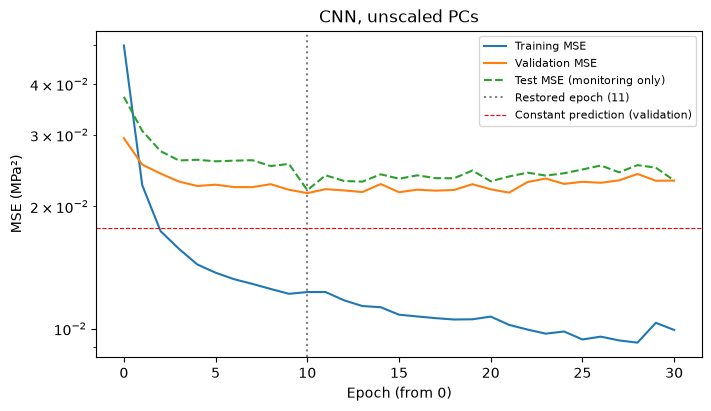

In [106]:
rows = []
for split in ("train", "val", "test"):
    s = result["scores"][split]                                 # R² and RMSE of this set
    std = targets_phys[split].std()                             # standard deviation of the measured target in this set
    rows.append({"set": split, "windows": len(targets_phys[split]), "loss (MSE)": result["final_loss"][split],
                 "R2": s["r2"], "RMSE": s["rmse"], "target std": std, "RMSE / std": s["rmse"] / std})
display(pd.DataFrame(rows).set_index("set").round(6))           # summary table
print(f"RMSE and target std in {target_unit}; restored epoch {result['best_epoch']} of {result['epochs_run']}")

baseline_val = float(np.mean((y_val - y_train.mean()) ** 2))    # validation MSE of a constant prediction equal to the training mean

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(result["history"]["loss"], label="Training MSE")        # training loss per epoch
ax.plot(result["history"]["val_loss"], label="Validation MSE")  # validation loss per epoch
ax.plot(result["history"]["test_loss"], label="Test MSE (monitoring only)", ls="--")   # test loss per epoch, never used to choose the epoch
ax.axvline(result["best_epoch"] - 1, color="gray", ls=":", label=f"Restored epoch ({result['best_epoch']})")   # epoch chosen by early stopping
ax.axhline(baseline_val, color="red", ls="--", lw=0.8, label="Constant prediction (validation)")               # level to beat
ax.set(xlabel="Epoch (from 0)", ylabel="MSE (scaled target)" if SCALE_TARGET else "MSE (MPa²)",
       yscale="log", title=result["name"])
ax.legend(fontsize=8)
plt.show()

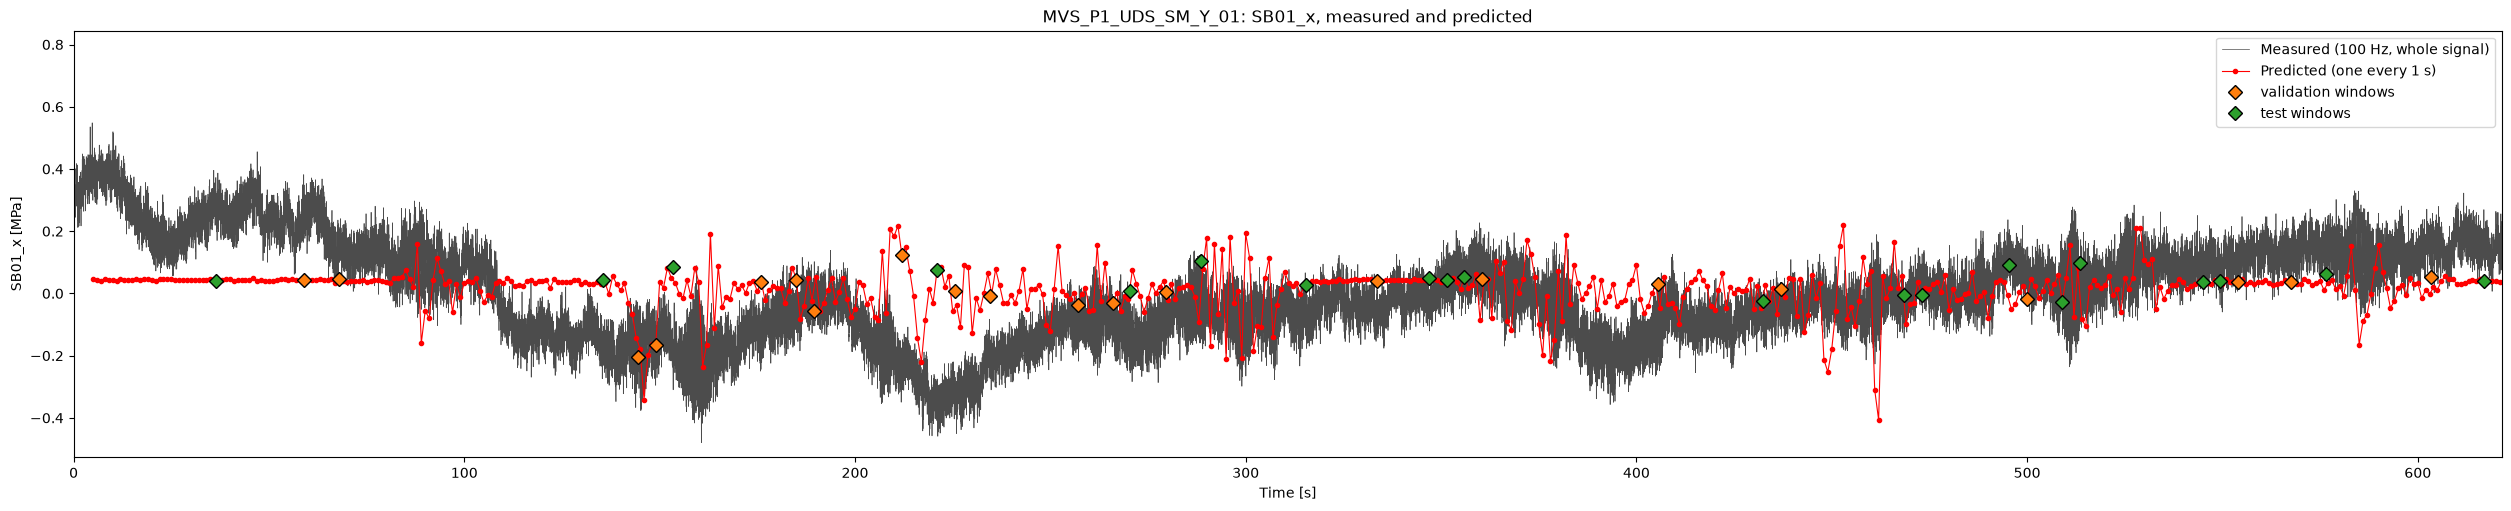

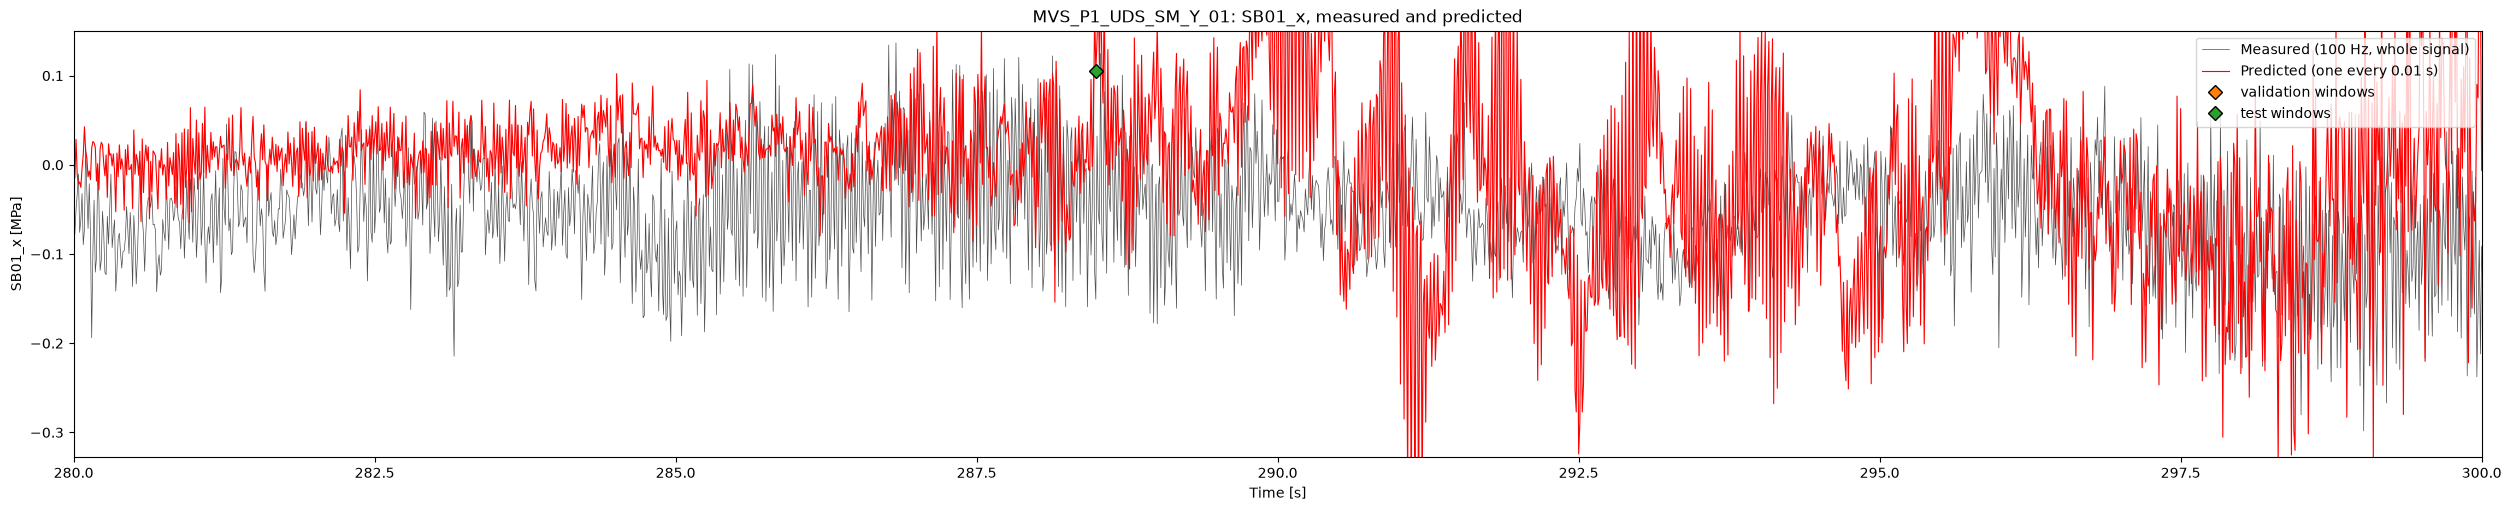

In [107]:
PRED_STEP_S = 1.0                                             # seconds between two predictions drawn in the plot
FIG_SIZE = (25, 5)                                            # figure size in inches

def predict_every(model, n, step_s, t_range=None, batch=256):
    """Predictions for windows that end every step_s seconds, inside t_range (the whole recording n by default)."""
    r = reduced_full[n]                                       # PCs of the whole recording
    Z = r[pc_cols].values.astype("float32")
    step = max(1, int(round(step_s * fs)))                    # step in samples
    ends = np.arange(LONG_WIN - 1, len(Z), step)              # last sample of every window to predict
    if t_range is not None:                                   # keep only the windows that end inside the interval shown
        times = r.index.values[ends]
        ends = ends[(times >= t_range[0]) & (times <= t_range[1])]
    sw = sliding_window_view(Z, LONG_WIN, axis=0)             # all windows as a view, no copy
    out = []
    for start in range(0, len(ends), batch):                  # predict in chunks to limit the memory
        idx = ends[start:start + batch] - (LONG_WIN - 1)      # first row of each window in this chunk
        chunk = np.ascontiguousarray(sw[idx].transpose(0, 2, 1))
        out.append(model.predict(chunk, batch_size=batch, verbose=0).ravel())   # predictions in the network's units
    return r.index.values[ends], to_physical(np.concatenate(out))   # times and predictions in MPa

def plot_prediction(n, step_s=PRED_STEP_S, t_range=None, held_out=True, fig_size=FIG_SIZE):
    """Whole measured signal, and the prediction at some intervals; validation and test windows are highlighted."""
    d = recordings[n]
    t_range = t_range or (d.index[0], d.index[-1])            # time interval to show: the whole recording by default
    with keras.device(DEVICE):
        t_p, y_p = predict_every(result["model"], n, step_s, t_range)   # prediction every step_s seconds, only where it is shown
    fig, ax = plt.subplots(figsize=fig_size, constrained_layout=True)
    ax.plot(d.index, d[TARGET], color="black", lw=0.5, alpha=0.7, label="Measured (100 Hz, whole signal)")
    ax.plot(t_p, y_p, "-o" if step_s >= 0.2 else "-", color="red", lw=0.8, ms=3,    # dots only when the predictions are few
            label=f"Predicted (one every {step_s:g} s)")
    if held_out:                                              # the windows that were NOT used to train the weights
        rec_id = used_names.index(n)
        for label, t_s, y_s, rec_s, color in (("validation windows", t_val, result["predictions"]["val"], rec_val, "tab:orange"),
                                              ("test windows", t_test, result["predictions"]["test"], rec_test, "tab:green")):
            m = rec_s == rec_id                               # windows of this recording
            ax.plot(t_s[m], y_s[m], "D", color=color, ms=7, mec="black", label=label)
    ax.set_xlim(*t_range)
    visible = d.loc[t_range[0]:t_range[1], TARGET]
    ax.set_ylim(visible.min() * 1.1, visible.max() * 1.1)     # vertical scale fitted to the part shown
    ax.set(title=f"{n}: {TARGET}, measured and predicted", xlabel="Time [s]", ylabel=f"{TARGET} [{target_unit}]")
    ax.legend(loc="upper right")
    plt.show()
    return fig

plot_prediction(rec_names[0]);                                # the whole first recording
plot_prediction(rec_names[0], step_s=0.01, t_range=(280, 300));  # zoom on 40 s, a prediction at every sample (0.01 s)